# Video Game Sales Prediction on Steam Data
## Notebook 6 — Modification 3: The Second Parent Paper's Approach

**Second parent paper.** Bondarenko, V., Cabrera, J. A. & Fitzek, F. H. P. (2026). *Predicting Early Sales of
PC Games Using Steam Wishlists and User Ratings.* IEEE International Conference on Smart Applications,
Communications and Networking (SmartNets), Rome. DOI 10.1109/SMARTNETS69662.2026.11604668.

The paper studies 1,545 first-time Steam releases from July to November 2025 (1,202 paid and 343 free-to-play
games). Its outcome is **conversion**: reviews in the first 30 days divided by launch-day wishlists, a proxy for
the share of wishlisters who buy the game. It fits ordinary least squares on log(conversion) with **separate
models for paid and free-to-play games**, groups price into **price bands**, and reports every coefficient as a
**percentage change**. For example, 10 more rating points go with 22% (paid) and 28% (free-to-play) higher
conversion, and a $10 higher price with 15% lower conversion. Its R² is 0.106 (paid) and 0.164 (free-to-play).

**What is borrowed and what is not.** The paper's main variables cannot be used here. Steam wishlists are not
in this dataset, and the 30-day user rating only exists after release, so using it would bring back the
leakage removed from the first parent paper. Only the paper's **approach** is borrowed:

| | Paper | This notebook |
|---|---|---|
| Outcome | log(30-day conversion of wishlists) | log(estimated owners), the target of Notebooks 3–5 |
| Main predictors | Launch-day wishlists, 30-day user rating | **Not used**: not available, or known only after release |
| Segments | Separate paid and free-to-play models | **Borrowed** |
| Price | Price bands | **Borrowed** (the paper's bands, plus $80+) |
| Reporting | Percentage effects with p-values and 95% confidence intervals | **Borrowed** |
| Sample | Top games by 30-day reviews in five months | All 76,727 labeled games from 1997–2024, not selected on the outcome; release-year controls added |
| Validation | In-sample R² only | In-sample R², **and** the 5-fold cross-validation of Notebooks 3–5 |

Because the outcome, sample and controls differ, the coefficients here are **not** directly comparable with the
paper's. The comparison concerns the approach and the direction of effects. The user rating is never a model
input. It appears only in the write-up (Section 4), as a clearly labelled post-release diagnostic.

**Questions.**
1. Do store-page features relate to sales differently for paid and free-to-play games?
2. Do the paper's two modelling devices, separate segments and price bands, improve predictions for games the
   model has not seen?

The same analysis is recorded as experiments E04 and E05 in `experiments/EXPERIMENT_LOG.md`, with a longer
write-up in `experiments/paper2_style/PAPER2_STYLE_ANALYSIS.md`.

In [1]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold, train_test_split

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
})
BLUE, GREEN, ORANGE, RED, GREY, PURPLE = "#4C72B0", "#55A868", "#DD8452", "#C44E52", "#8C8C8C", "#8172B3"
RANDOM_STATE = 42

FIG_DIR = os.path.join("..", "outputs", "figures")
TAB_DIR = os.path.join("..", "outputs", "tables")
DATA_DIR = os.path.join("..", "data", "processed")

data = pd.read_csv(os.path.join(DATA_DIR, "steam_model_table.csv.gz"), parse_dates=["release_dt"])
with open(os.path.join(DATA_DIR, "features.json")) as f:
    spec = json.load(f)
FEATURES = spec["numeric"] + spec["genres"] + spec["categories"]
data["owners"] = (data["owners_millions"] * 1e6).round()   # midpoint of the SteamSpy owner range
data["log_owners"] = np.log(data["owners"])                # owners are at least 10,000, so no offset is needed
data["description_length_1000"] = data["description_length"] / 1000   # effects reported per 1,000 characters
data["segment"] = np.where(data["price"] > 0, "paid", "free-to-play")

# The paper's price bands, plus one band for prices of $80 and above
BAND_EDGES = [0.0, 10, 20, 30, 40, 60, 80, np.inf]
BAND_LABELS = ["$0.99–9.99", "$10–19.99", "$20–29.99", "$30–39.99", "$40–59.99", "$60–79.99", "$80+"]
data["price_band"] = pd.cut(data["price"], BAND_EDGES, labels=BAND_LABELS, right=False)
data.loc[data["segment"] == "free-to-play", "price_band"] = np.nan

paid, free = data[data["segment"] == "paid"], data[data["segment"] == "free-to-play"]
print(f"{len(data):,} games | paid (price > 0): {len(paid):,} | free-to-play (price = 0): {len(free):,}")

76,727 games | paid (price > 0): 68,380 | free-to-play (price = 0): 8,347


---
# 11. Modification 3: The Second Parent Paper's Approach

## 11.1 Descriptive tables in the paper's format

The paper describes each group by its number of games and the mean and median of its outcome. The same format
is used here for owners, first by business model and then by price band for paid games. The median is often
10,000, the midpoint of the lowest owner range, so the share of games reaching 100,000 owners is added.

,Games,Mean owners,Median owners,Share with 100k+ owners
segment,,,,
paid,"68,380","105,837","10,000",10.0%
free-to-play,"8,347","287,642","10,000",16.6%


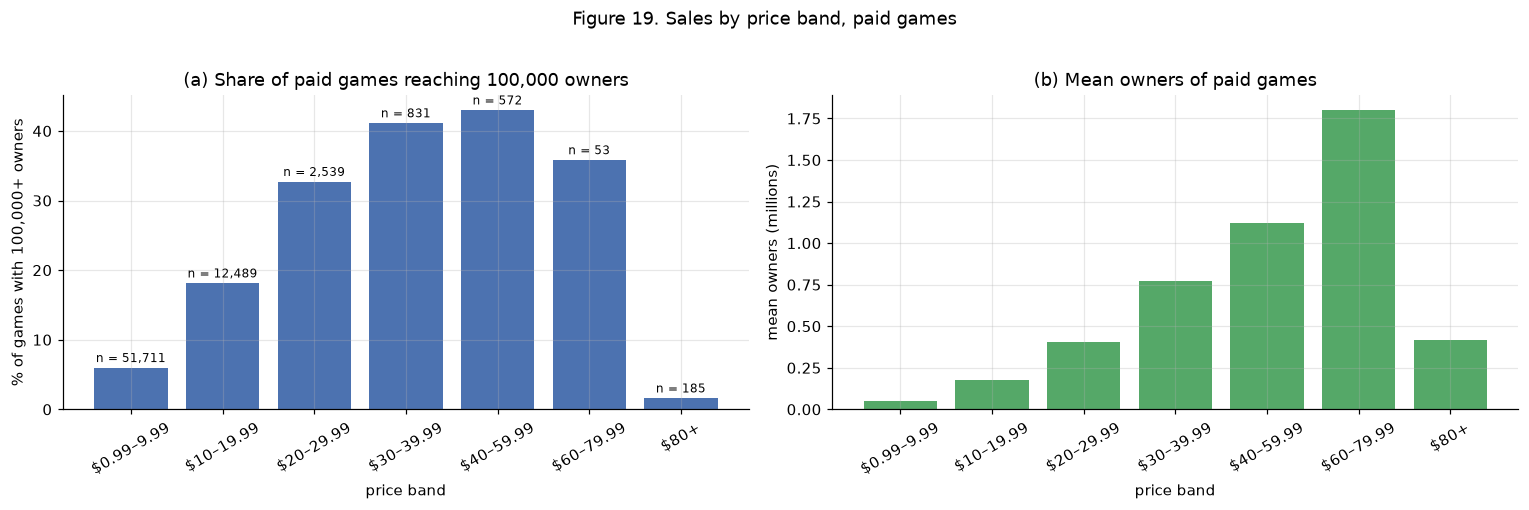

,Games,Mean owners,Median owners,Share with 100k+ owners
price_band,,,,
$0.99–9.99,"51,711","49,242","10,000",6.0%
$10–19.99,"12,489","176,082","10,000",18.1%
$20–29.99,"2,539","407,576","35,000",32.7%
$30–39.99,831,"773,724","35,000",41.2%
$40–59.99,572,"1,120,350","75,000",43.0%
$60–79.99,53,"1,800,660","10,000",35.8%
$80+,185,"419,541","10,000",1.6%


In [2]:
def describe(frame, key):
    g = frame.groupby(key, observed=True)["owners"]
    return pd.DataFrame({"Games": g.size(), "Mean owners": g.mean(), "Median owners": g.median(),
                         "Share with 100k+ owners": g.apply(lambda s: (s >= 1e5).mean())})


table25 = describe(data, "segment").loc[["paid", "free-to-play"]]
table26 = describe(paid, "price_band")
table25.to_csv(os.path.join(TAB_DIR, "table25_business_model.csv"))
table26.to_csv(os.path.join(TAB_DIR, "table26_price_bands_paid.csv"))
fmt = {"Games": "{:,}", "Mean owners": "{:,.0f}", "Median owners": "{:,.0f}", "Share with 100k+ owners": "{:.1%}"}
display(table25.style.format(fmt).set_caption("Table 25. Paid and free-to-play games"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
bands = table26.index.astype(str)
axes[0].bar(bands, 100 * table26["Share with 100k+ owners"], color=BLUE)
for i, (share, n) in enumerate(zip(table26["Share with 100k+ owners"], table26["Games"])):
    axes[0].text(i, 100 * share + 0.8, f"n = {n:,}", ha="center", fontsize=8)
axes[0].set_ylabel("% of games with 100,000+ owners")
axes[0].set_title("(a) Share of paid games reaching 100,000 owners")
axes[1].bar(bands, table26["Mean owners"] / 1e6, color=GREEN)
axes[1].set_ylabel("mean owners (millions)")
axes[1].set_title("(b) Mean owners of paid games")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
    ax.set_xlabel("price band")
fig.suptitle("Figure 19. Sales by price band, paid games", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig19_price_bands.png"), dpi=150, bbox_inches="tight")
plt.show()
table26.style.format(fmt).set_caption("Table 26. Paid games by price band")

**Interpretation.**
- **Free-to-play games reach larger audiences on average.** Their mean is 287,642 owners, against 105,837 for
  paid games, and 16.6% reach 100,000 owners, against 10.0%. The typical game in both groups is still in the
  lowest owner range (median 10,000).
- **Higher price bands go with far higher sales, up to $60.** The share of paid games reaching 100,000 owners
  rises from 6.0% at $0.99–9.99 to 43.0% at $40–59.99. Mean owners rise from 49,242 to 1.1 million. The pattern
  breaks at the top. The $60–79.99 band has only 53 games, and the $80+ band has the lowest share of all (1.6%
  of 185 games, mostly niche or unusually priced listings).
- **This is the opposite direction to the paper's price effect, and both can be true.** The paper finds that a
  higher price lowers *conversion*: among people who have already wishlisted a game, fewer buy it when it costs
  more. Here a higher price goes with *more* owners, because price also signals a bigger production aimed at a
  bigger audience. The two outcomes measure different things.

## 11.2 Percentage effects from separate paid and free-to-play models

**Model.** As in the paper, ordinary least squares is fitted to the logarithm of the outcome, separately for
paid and free-to-play games. A coefficient *b* then means that a one-unit increase in the variable goes with a
change of 100 × (e^*b* − 1)% in owners, holding the other variables fixed. For a yes/no feature, one unit means
having the feature.

**Variables.** All are known at release:
- **Price band** (paid games only), relative to $0.99–9.99.
- **Genres** with at least 30 games in the segment.
- **Store-page features**: supported languages, full-audio languages, screenshots, and description length per
  1,000 characters.
- **Platform and play features**: Mac, Linux, required age, single-player, multi-player, online PvP, online
  co-op, full controller support and VR only.
- **Release-year indicators**, with 2020 as the reference year. They absorb the time-on-sale effect found in
  Notebook 5; the paper did not need them because it covered five months.

These regressions describe the data, as in the paper, so they use all games and report in-sample R². Whether
the approach also predicts better is tested separately in Section 11.3 with the usual protocol.

In [3]:
GENRES = ["genre_Action", "genre_Adventure", "genre_RPG", "genre_Simulation", "genre_Strategy",
          "genre_Sports", "genre_Casual", "genre_Indie", "genre_Massively_Multiplayer", "genre_Racing"]
STORE_PAGE = ["n_languages", "n_audio_languages", "n_screenshots", "description_length_1000"]
PLATFORM_PLAY = ["mac", "linux", "required_age", "cat_Single_player", "cat_Multi_player", "cat_Online_PvP",
                 "cat_Online_Co_op", "cat_Full_controller_support", "cat_VR_Only"]


def ols(frame, columns):
    """OLS of log(owners) on `columns`. Coefficients are converted to percentage effects, 100 × (exp(b) − 1),
    with 95% confidence intervals and two-sided p-values from classical standard errors."""
    X = np.column_stack([np.ones(len(frame))] + [frame[c].astype(float).to_numpy() for c in columns])
    y = frame["log_owners"].to_numpy()
    xtx_inv = np.linalg.pinv(X.T @ X)
    beta = xtx_inv @ X.T @ y
    resid = y - X @ beta
    dof = len(y) - X.shape[1]
    se = np.sqrt(np.diag(resid @ resid / dof * xtx_inv))
    t_crit = stats.t.ppf(0.975, dof)
    out = pd.DataFrame({"variable": ["(intercept)"] + list(columns), "coef": beta, "std_error": se,
                        "p_value": 2 * stats.t.sf(np.abs(beta / se), dof)}).set_index("variable")
    out["effect (%)"] = 100 * (np.exp(out["coef"]) - 1)
    out["CI low (%)"] = 100 * (np.exp(out["coef"] - t_crit * se) - 1)
    out["CI high (%)"] = 100 * (np.exp(out["coef"] + t_crit * se) - 1)
    r2 = 1 - resid @ resid / ((y - y.mean()) @ (y - y.mean()))
    return out, r2


def year_dummies(frame, ref_year=2020):
    """Release-year indicators for years with at least 30 games in the frame."""
    return pd.DataFrame({f"year_{y}": (frame["release_year"] == y).astype(int)
                         for y in sorted(frame["release_year"].unique())
                         if y != ref_year and (frame["release_year"] == y).sum() >= 30}, index=frame.index)


def band_dummies(frame, ref="$0.99–9.99"):
    return pd.DataFrame({f"price_{b}": (frame["price_band"] == b).astype(int) for b in BAND_LABELS if b != ref},
                        index=frame.index)


effects, r2_in_sample = {}, {}
for seg, frame in [("paid", paid), ("free-to-play", free)]:
    f = pd.concat([frame, year_dummies(frame)], axis=1)
    years = [c for c in f.columns if c.startswith("year_")]
    columns = [g for g in GENRES if f[g].sum() >= 30] + STORE_PAGE + PLATFORM_PLAY + years
    if seg == "paid":
        f = pd.concat([f, band_dummies(f)], axis=1)
        columns = [c for c in f.columns if c.startswith("price_$")] + columns
    effects[seg], r2_in_sample[seg] = ols(f, columns)
    print(f"{seg}: {len(f):,} games | {len(columns)} variables, of which {len(years)} release-year indicators "
          f"| in-sample R² = {r2_in_sample[seg]:.3f}")

# The paper's "per +$10" effect: the same paid-game model with one continuous price variable instead of bands
f = pd.concat([paid, year_dummies(paid)], axis=1)
f["price_per_10"] = f["price"] / 10
continuous, _ = ols(f, ["price_per_10"] + [g for g in GENRES if f[g].sum() >= 30] + STORE_PAGE + PLATFORM_PLAY
                    + [c for c in f.columns if c.startswith("year_")])
e = continuous.loc["price_per_10"]
print(f"Paid games, continuous price: +$10 goes with {e['effect (%)']:+.1f}% owners "
      f"(95% CI {e['CI low (%)']:+.1f}% to {e['CI high (%)']:+.1f}%, "
      f"p {'< 0.001' if e['p_value'] < 0.001 else '= ' + format(e['p_value'], '.3f')})")

paid: 68,380 games | 47 variables, of which 18 release-year indicators | in-sample R² = 0.316
free-to-play: 8,347 games | 35 variables, of which 12 release-year indicators | in-sample R² = 0.288
Paid games, continuous price: +$10 goes with +9.8% owners (95% CI +9.2% to +10.5%, p < 0.001)


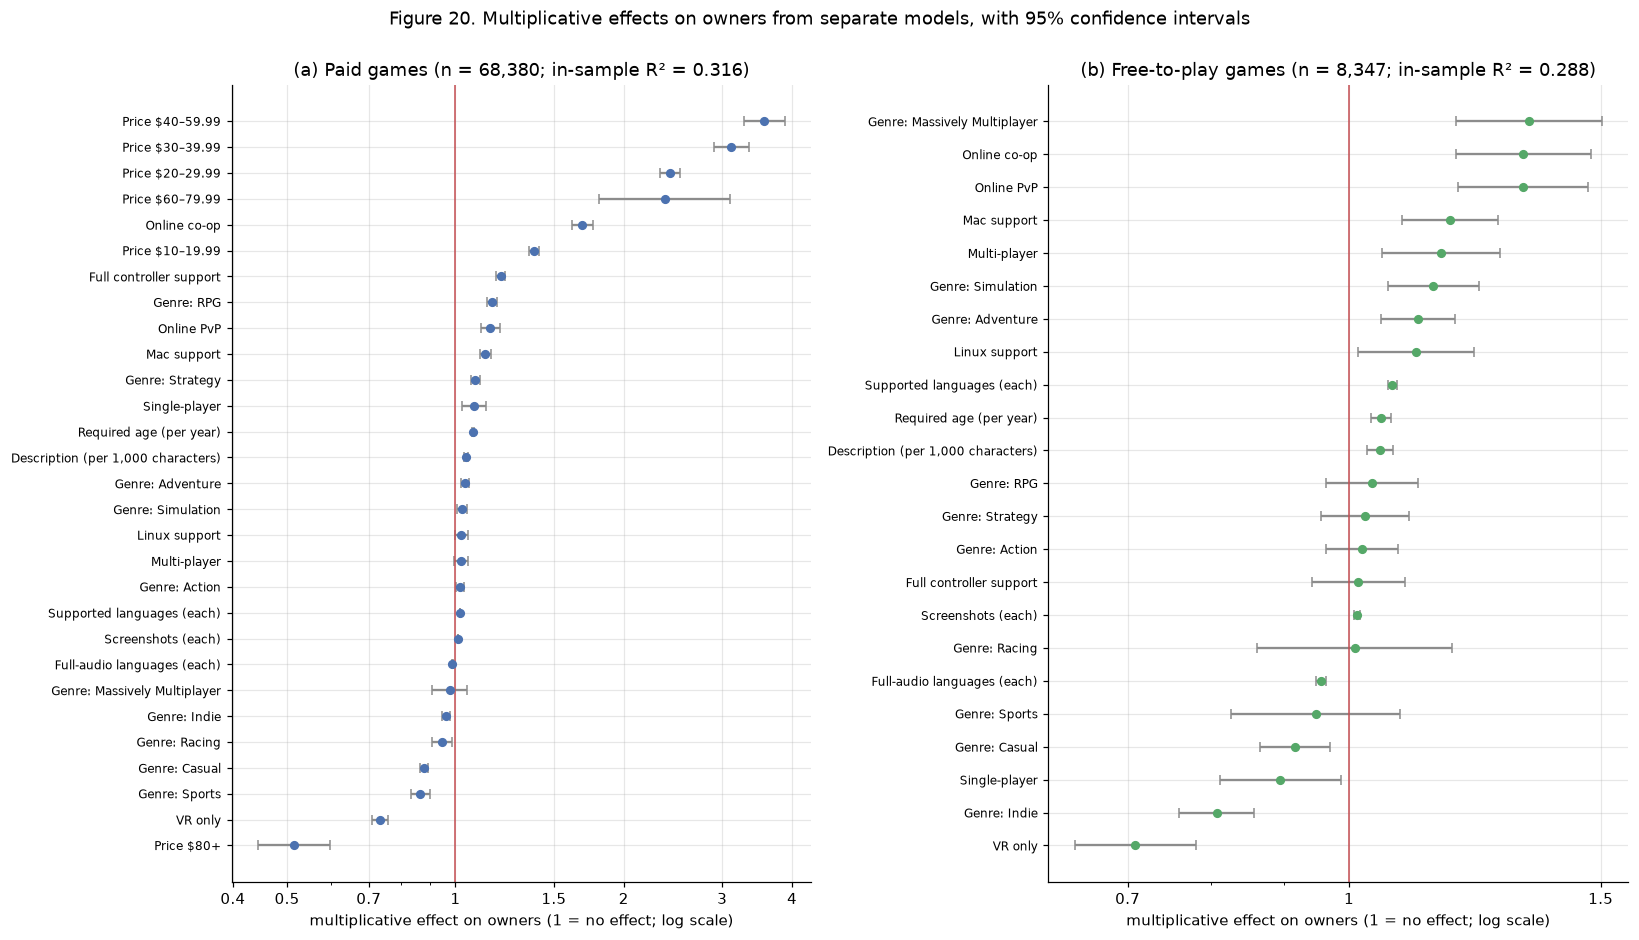

,Paid: effect [95% CI],Paid: p,Free-to-play: effect [95% CI],Free-to-play: p
Variable,,,,
Price $10–19.99,"+38.4% [+35.6, +41.3]",<0.001,—,—
Price $20–29.99,"+141.8% [+132.0, +151.9]",<0.001,—,—
Price $30–39.99,"+211.7% [+190.5, +234.3]",<0.001,—,—
Price $40–59.99,"+257.0% [+228.2, +288.4]",<0.001,—,—
Price $60–79.99,"+137.0% [+81.0, +210.3]",<0.001,—,—
Price $80+,"-48.6% [-55.6, -40.4]",<0.001,—,—
Genre: Action,"+2.0% [+0.4, +3.7]",0.016,"+2.1% [-3.6, +8.1]",0.484
Genre: Adventure,"+3.9% [+2.3, +5.6]",<0.001,"+11.7% [+5.3, +18.5]",<0.001
Genre: RPG,"+16.3% [+14.0, +18.7]",<0.001,"+3.8% [-3.6, +11.8]",0.322


In [4]:
NAMES = {
    "n_languages": "Supported languages (each)", "n_audio_languages": "Full-audio languages (each)",
    "n_screenshots": "Screenshots (each)", "description_length_1000": "Description (per 1,000 characters)",
    "mac": "Mac support", "linux": "Linux support", "required_age": "Required age (per year)",
    "cat_Single_player": "Single-player", "cat_Multi_player": "Multi-player", "cat_Online_PvP": "Online PvP",
    "cat_Online_Co_op": "Online co-op", "cat_Full_controller_support": "Full controller support",
    "cat_VR_Only": "VR only",
}


def label(v):
    if v.startswith("price_"):
        return f"Price {v[6:]}"
    if v.startswith("genre_"):
        return "Genre: " + v[6:].replace("_", " ")
    return NAMES.get(v, v)


def shown(table):
    return [v for v in table.index if v != "(intercept)" and not v.startswith("year_")]


variables = shown(effects["paid"]) + [v for v in shown(effects["free-to-play"]) if v not in shown(effects["paid"])]
rows = []
for v in variables:
    row = {"Variable": label(v)}
    for seg, name in [("paid", "Paid"), ("free-to-play", "Free-to-play")]:
        t = effects[seg]
        if v in t.index:
            r = t.loc[v]
            row[f"{name}: effect [95% CI]"] = f"{r['effect (%)']:+.1f}% [{r['CI low (%)']:+.1f}, {r['CI high (%)']:+.1f}]"
            row[f"{name}: p"] = "<0.001" if r["p_value"] < 0.001 else f"{r['p_value']:.3f}"
        else:
            row[f"{name}: effect [95% CI]"], row[f"{name}: p"] = "—", "—"
    rows.append(row)
table27 = pd.DataFrame(rows).set_index("Variable")
pd.concat([effects["paid"].assign(segment="paid"), effects["free-to-play"].assign(segment="free-to-play")]) \
    .to_csv(os.path.join(TAB_DIR, "table27_percentage_effects.csv"))

fig, axes = plt.subplots(1, 2, figsize=(15, 8.5))
for ax, seg, color in [(axes[0], "paid", BLUE), (axes[1], "free-to-play", GREEN)]:
    t = effects[seg].loc[shown(effects[seg])].copy()
    t["ratio"] = np.exp(t["coef"])
    t = t.sort_values("ratio")
    ypos = np.arange(len(t))
    low, high = 1 + t["CI low (%)"] / 100, 1 + t["CI high (%)"] / 100
    ax.errorbar(t["ratio"], ypos, xerr=[t["ratio"] - low, high - t["ratio"]], fmt="o", color=color, ecolor=GREY,
                capsize=3, markersize=5)
    ax.axvline(1, color=RED, lw=1)
    ax.set_yticks(ypos)
    ax.set_yticklabels([label(v) for v in t.index], fontsize=8)
    ax.set_xscale("log")
    lo, hi = ax.get_xlim()
    ticks = [t for t in [0.4, 0.5, 0.7, 1, 1.5, 2, 3, 4] if lo <= t <= hi]
    ax.set_xticks(ticks)
    ax.set_xticklabels([f"{t:g}" for t in ticks])
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_xlabel("multiplicative effect on owners (1 = no effect; log scale)")
    ax.set_title(f"({'a' if seg == 'paid' else 'b'}) {seg.capitalize()} games "
                 f"(n = {len(paid if seg == 'paid' else free):,}; in-sample R² = {r2_in_sample[seg]:.3f})")
fig.suptitle("Figure 20. Multiplicative effects on owners from separate models, with 95% confidence intervals", y=1.0)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig20_effects_paid_vs_free.png"), dpi=150, bbox_inches="tight")
plt.show()
table27.style.set_caption("Table 27. Percentage effects on owners (log-linear OLS with release-year controls; "
                          "price relative to $0.99–9.99)")

**Interpretation.**
- **Paid games (Figure 20a).** With genre, store page, platform and release year held fixed, price bands still
  have the largest effects. Compared with $0.99–9.99, games at $20–29.99 have 142% more owners, at $30–39.99
  212% more and at $40–59.99 257% more, while games at $80+ have 49% fewer. Online co-op (+69%) and full
  controller support (+21%) are the strongest design features, and VR-only is the strongest negative (−27%).
- **Free-to-play games (Figure 20b).** Price does not apply. The strongest positive effects are multiplayer:
  massively multiplayer (+34%), online co-op (+32%) and online PvP (+32%). Indie (−19%) and VR-only (−29%) are the
  strongest negatives.
- **The same feature can matter very differently in each segment.** This is what separate models reveal:
  - **Localisation:** each supported language goes with +7.2% owners for free-to-play games, four times the
    +1.8% for paid games.
  - **Single-player mode:** +8.0% for paid games, but −10.5% for free-to-play games.
  - **Full controller support:** +21% for paid games, but no clear effect for free-to-play games (+1.5%,
    p = 0.69).
- **With one continuous price** instead of bands, each +$10 goes with **+9.8% owners** (95% CI +9.2% to +10.5%).
  The paper finds −15% conversion per $10, but as Section 11.1 explains, the outcomes differ.
- **In-sample R² is 0.316 (paid) and 0.288 (free-to-play)**, against the paper's 0.106 and 0.164. The outcome,
  sample and controls all differ, so this does not show that this model is better.
- **Full-audio languages gets a negative coefficient in both segments.** Every full-audio language is also a
  supported language, and the two counts are strongly correlated (0.79), so they should be read together, not
  one at a time.

## 11.3 Do the paper's devices improve prediction?

The paper never tests its predictions on held-out data. Here both devices are tested with the protocol of
Notebooks 3–5: the same training set and folds, and the log1p(owners) target. Two models are compared: Linear
Regression, the paper's type of model, and Gradient Boosting, the best model of Notebook 5. Each is run in
four variants: one pooled model or separate paid and free-to-play models, with price either continuous or in
bands. R² is computed over all out-of-fold predictions together, so the paid and free-to-play games can also
be scored separately.

Linear Regression: done
Gradient Boosting: done


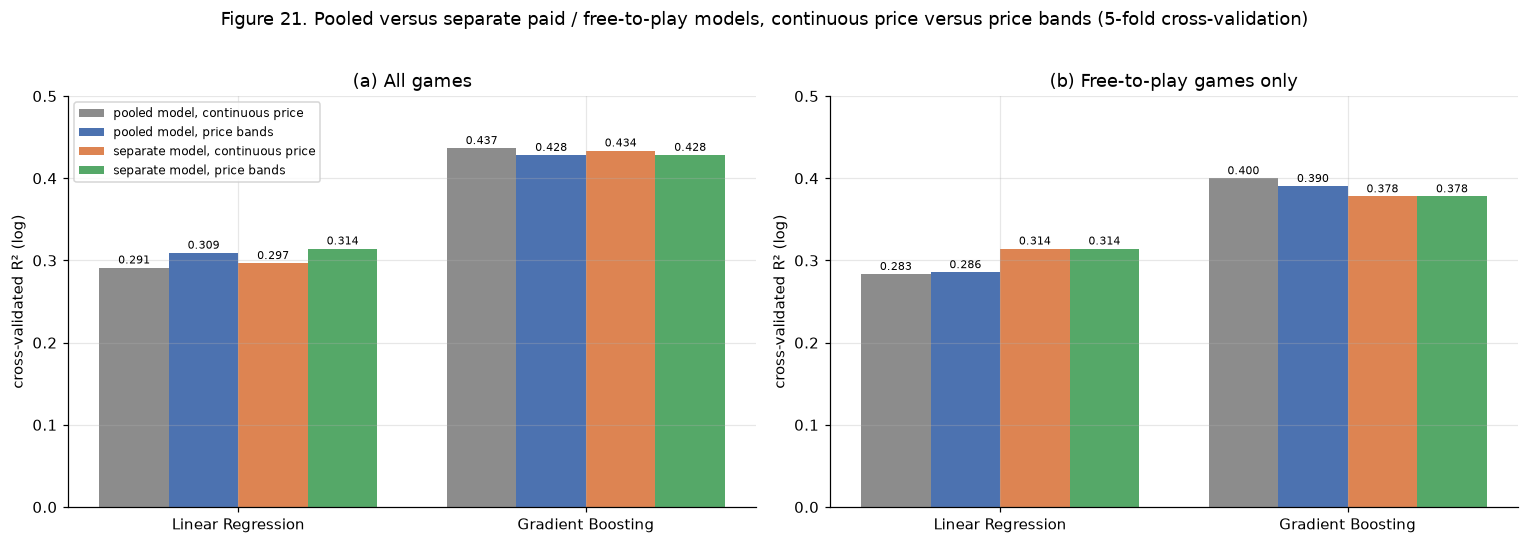

In [5]:
train, _ = train_test_split(data, test_size=0.2, random_state=RANDOM_STATE)
train = train.reset_index(drop=True)
folds = list(KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(train))
y = np.log1p(train["owners"].to_numpy())
segment = train["segment"].to_numpy()
band_columns = pd.get_dummies(train["price_band"], prefix="band").astype(int)
train = pd.concat([train, band_columns], axis=1)
FEATURES_BANDS = [c for c in FEATURES if c != "price"] + list(band_columns.columns)

rows, oof_all = [], {}
for model_name, model in [("Linear Regression", LinearRegression()),
                          ("Gradient Boosting", HistGradientBoostingRegressor(random_state=RANDOM_STATE))]:
    for segments in ["pooled", "separate"]:
        for price, feats in [("continuous", FEATURES), ("bands", FEATURES_BANDS)]:
            oof = np.zeros(len(train))
            for tr, va in folds:
                if segments == "pooled":
                    oof[va] = clone(model).fit(train.loc[tr, feats], y[tr]).predict(train.loc[va, feats])
                else:
                    for s in ["paid", "free-to-play"]:
                        tr_s, va_s = tr[segment[tr] == s], va[segment[va] == s]
                        oof[va_s] = clone(model).fit(train.loc[tr_s, feats], y[tr_s]).predict(train.loc[va_s, feats])
            is_free = segment == "free-to-play"
            rows.append({"Model": model_name, "Segments": segments, "Price": price,
                         "R² (log), all games": r2_score(y, oof),
                         "R² (log), paid": r2_score(y[~is_free], oof[~is_free]),
                         "R² (log), free-to-play": r2_score(y[is_free], oof[is_free]),
                         "MAE (log), free-to-play": mean_absolute_error(y[is_free], oof[is_free])})
    print(f"{model_name}: done")
table28 = pd.DataFrame(rows).set_index(["Model", "Segments", "Price"])
table28.to_csv(os.path.join(TAB_DIR, "table28_pooled_vs_separate_cv.csv"))

variants = [("pooled", "continuous"), ("pooled", "bands"), ("separate", "continuous"), ("separate", "bands")]
variant_colors = [GREY, BLUE, ORANGE, GREEN]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, column, title in [(axes[0], "R² (log), all games", "(a) All games"),
                          (axes[1], "R² (log), free-to-play", "(b) Free-to-play games only")]:
    for i, ((segments, price), color) in enumerate(zip(variants, variant_colors)):
        values = [table28.loc[(m, segments, price), column] for m in ["Linear Regression", "Gradient Boosting"]]
        xs = np.arange(2) + (i - 1.5) * 0.2
        ax.bar(xs, values, 0.2, color=color,
               label=f"{segments} model, " + ("price bands" if price == "bands" else "continuous price"))
        for xi, v in zip(xs, values):
            ax.text(xi, v + 0.005, f"{v:.3f}", ha="center", fontsize=7)
    ax.set_xticks(np.arange(2))
    ax.set_xticklabels(["Linear Regression", "Gradient Boosting"])
    ax.set_ylim(0, 0.5)
    ax.set_ylabel("cross-validated R² (log)")
    ax.set_title(title)
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle("Figure 21. Pooled versus separate paid / free-to-play models, continuous price versus price bands "
             "(5-fold cross-validation)", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig21_pooled_vs_separate.png"), dpi=150, bbox_inches="tight")
plt.show()
table28.style.format("{:.3f}").set_caption(
    "Table 28. Cross-validated accuracy of the four variants (log1p owners; R² over all out-of-fold predictions)")

**Interpretation.**
- **For Linear Regression, both devices help.**
  - Price bands add +0.018 R² (0.291 → 0.309).
  - Separate models add +0.005 (0.291 → 0.297).
  - Together they add +0.023 (0.291 → 0.314).
  - For free-to-play games alone, separate models raise R² from 0.283 to 0.314.

  Bands let a linear model follow the non-linear price pattern of Section 11.1. Separate models let every
  coefficient differ by segment, which amounts to adding interactions by hand.
- **For Gradient Boosting, neither device helps.** R² changes by −0.003 with separate models and by −0.008
  with price bands. Gradient Boosting already finds non-linear price effects and interactions by itself. It
  also benefits from pooling: a separate free-to-play model learns from about 5,300 games per fold instead of
  about 49,000, and its R² on free-to-play games falls from 0.400 to 0.376.
- **Pooled Gradient Boosting with continuous price remains the best model** (0.437, as in Notebook 5).

---
## 11.4 Findings and decision

**Findings.**
1. **Separate paid and free-to-play models are useful for interpretation.** The same store-page feature
   carries a different weight in each segment. The clearest cases are localisation (+7.2% per language for
   free-to-play games against +1.8% for paid games) and multiplayer design, which matters more for
   free-to-play games.
2. **Price bands describe the price–sales relationship better than a single slope.** Owners rise steeply up to
   the $40–59.99 band and fall sharply above $80.
3. **The price effect points the other way from the paper's.** Here +$10 goes with +9.8% owners; in the paper
   it goes with −15% conversion. The outcomes differ: total owners here, conversion of existing wishlisters
   there.
4. **Neither device improves the best predictive model.** They help Linear Regression (+0.023 R²) but slightly
   hurt Gradient Boosting, which already captures non-linear effects and interactions.
5. **All effects are predictive associations, not causal effects.** Price, localisation and multiplayer
   support are chosen together with a game's budget and ambition, which the data do not show.

**Decision.**
- **Prediction:** pooled Gradient Boosting on log1p(owners) with continuous price (Notebook 5) stays the
  reference model.
- **Interpretation:** separate paid and free-to-play log-linear models, reported as percentage effects in the
  second parent paper's format, are adopted as its interpretable companion.
- **Linear models:** price bands are used.

**Next steps.** As in Notebook 5 (Section 10.9): chronological validation, then new pre-release features, one
group at a time. The paper's own predictors are not available before release in this dataset. The closest
substitute for its wishlist counts is a pre-release attention proxy, such as how long the store page was
online before release.